[[-2.26470281  0.4800266 ]
 [-2.08096115 -0.67413356]
 [-2.36422905 -0.34190802]
 [-2.29938422 -0.59739451]
 [-2.38984217  0.64683538]
 [-2.07563095  1.48917752]
 [-2.44402884  0.0476442 ]
 [-2.23284716  0.22314807]
 [-2.33464048 -1.11532768]
 [-2.18432817 -0.46901356]
 [-2.1663101   1.04369065]
 [-2.32613087  0.13307834]
 [-2.2184509  -0.72867617]
 [-2.6331007  -0.96150673]
 [-2.1987406   1.86005711]
 [-2.26221453  2.68628449]
 [-2.2075877   1.48360936]
 [-2.19034951  0.48883832]
 [-1.898572    1.40501879]
 [-2.34336905  1.12784938]
 [-1.914323    0.40885571]
 [-2.20701284  0.92412143]
 [-2.7743447   0.45834367]
 [-1.81866953  0.08555853]
 [-2.22716331  0.13725446]
 [-1.95184633 -0.62561859]
 [-2.05115137  0.24216355]
 [-2.16857717  0.52714953]
 [-2.13956345  0.31321781]
 [-2.26526149 -0.3377319 ]
 [-2.14012214 -0.50454069]
 [-1.83159477  0.42369507]
 [-2.61494794  1.79357586]
 [-2.44617739  2.15072788]
 [-2.10997488 -0.46020184]
 [-2.2078089  -0.2061074 ]
 [-2.04514621  0.66155811]
 

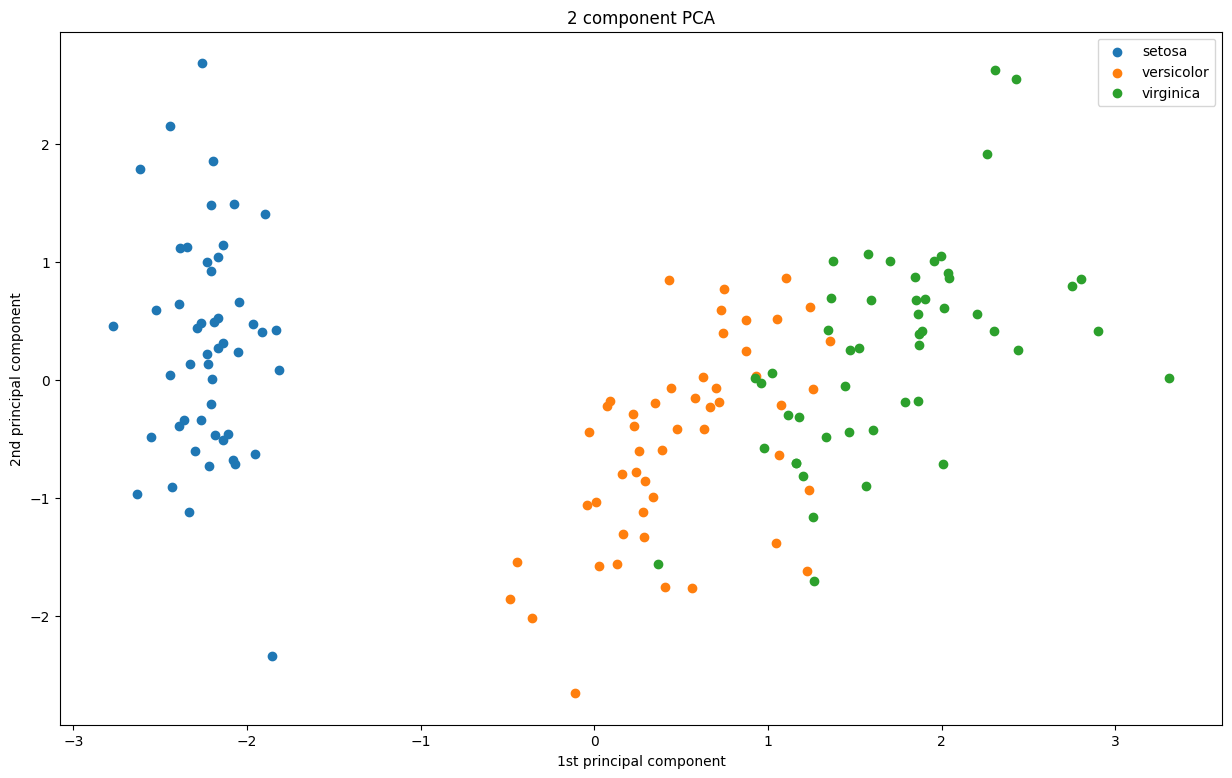

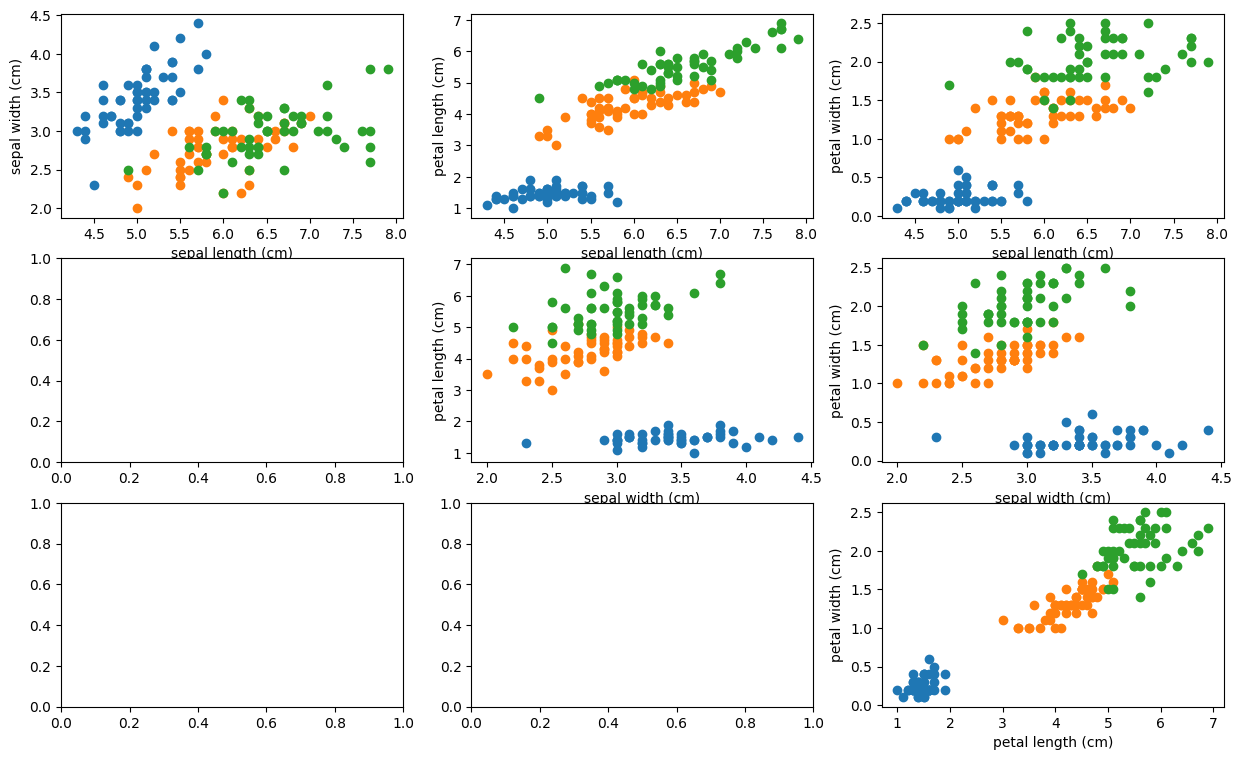

Score LDA sur les 2 premières composantes : 0.9333333333333333
Score LDA sur les données normalisées : 0.98


In [1]:
# Importation des bibliothèques nécessaires
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris  # Pour charger le dataset Iris
from sklearn.preprocessing import scale  # Pour normaliser les données
from sklearn.decomposition import PCA  # Pour effectuer l'analyse en composantes principales (PCA)
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA  # Pour l'analyse discriminante linéaire
import pandas as pd
from pandas_datareader import DataReader  # Pour récupérer les données boursières (pas utilisé ici)
import datetime as dt  # Pour manipuler les dates (pas utilisé ici)

# 1. Chargement des données Iris
iris = load_iris()  # Charge le dataset Iris
X = iris.data  # Données d'entrée (caractéristiques des fleurs)
y = iris.target  # Cibles (types de fleurs)

# 2. Normalisation des données avec la commande `scale`
Xscaled = scale(X)  # Normalisation des données pour que chaque caractéristique ait une moyenne de 0 et une variance de 1

# 3. Analyse en composantes principales (PCA) sur les données normalisées
# Nous réduisons la dimensionnalité des données à 2 composantes principales
pca = PCA(n_components=2)  # On choisit de réduire à 2 dimensions
pc = pca.fit_transform(Xscaled)  # Applique PCA aux données normalisées et récupère les 2 premières composantes principales
print(pc)  # Affiche les composantes principales obtenues

# 4. Calcul de la fraction de la variance expliquée par les 2 premières composantes
explained_variance = pca.explained_variance_ratio_.sum()  # La somme des variances expliquées par les 2 premières composantes
print(f"Fraction de la variance expliquée par les 2 premières composantes : {explained_variance}")

# 5. Visualisation des données projetées sur les 2 premières composantes principales
plt.rcParams['figure.figsize'] = (15, 9)  # Taille de la figure
for i in range(3):  # Les types de fleurs sont étiquetés par 0, 1 et 2
    idx = (y == i)  # On récupère les indices des fleurs de type i
    plt.scatter(pc[idx, 0], pc[idx, 1], label=iris.target_names[i])  # On trace les points correspondant à ce type de fleur
plt.title('2 component PCA')  # Titre du graphique
plt.xlabel('1st principal component')  # Légende de l'axe X
plt.ylabel('2nd principal component')  # Légende de l'axe Y
plt.legend()  # Affiche la légende avec les noms des types de fleurs
plt.show()  # Affiche le graphique

# 6. Trace des variables les unes contre les autres pour voir les relations entre elles
plt.rcParams['figure.figsize'] = (15, 9)  # Taille de la figure
fig, ax = plt.subplots(3, 3)  # Création d'une grille de 3x3 pour les sous-graphiques
for i in range(4):  # Les indices des caractéristiques sont 0, 1, 2, 3
    for j in range(4):  # Idem pour la deuxième caractéristique
        if i < j:  # On ne trace que les paires (i, j) où i < j pour éviter les doublons
            for k in range(3):  # On parcourt les 3 types de fleurs
                idx = (y == k)  # Récupère les indices des fleurs de type k
                ax[i][j-1].scatter(X[idx, i], X[idx, j], label=iris.target_names[k])  # Trace les points pour la paire (i, j)
                ax[i][j-1].set_xlabel(iris.feature_names[i])  # Légende de l'axe X
                ax[i][j-1].set_ylabel(iris.feature_names[j])  # Légende de l'axe Y
plt.show()  # Affiche le graphique des paires de caractéristiques

# 7. Analyse discriminante linéaire avec les 2 premières composantes principales
clf = LDA()  # On crée l'objet LDA
clf.fit(pc, y)  # On entraîne le modèle LDA sur les 2 premières composantes principales
print(f"Score LDA sur les 2 premières composantes : {clf.score(pc, y)}")  # Affiche le score de LDA sur les composantes principales

# 8. Comparaison avec les données initiales
clf = LDA()  # Crée un nouvel objet LDA
clf.fit(Xscaled, y)  # On entraîne le modèle LDA sur les données normalisées complètes
print(f"Score LDA sur les données normalisées : {clf.score(Xscaled, y)}")  # Affiche le score de LDA sur les données normalisées


Précision moyenne par validation croisée : 0.98 (+/- 0.03)


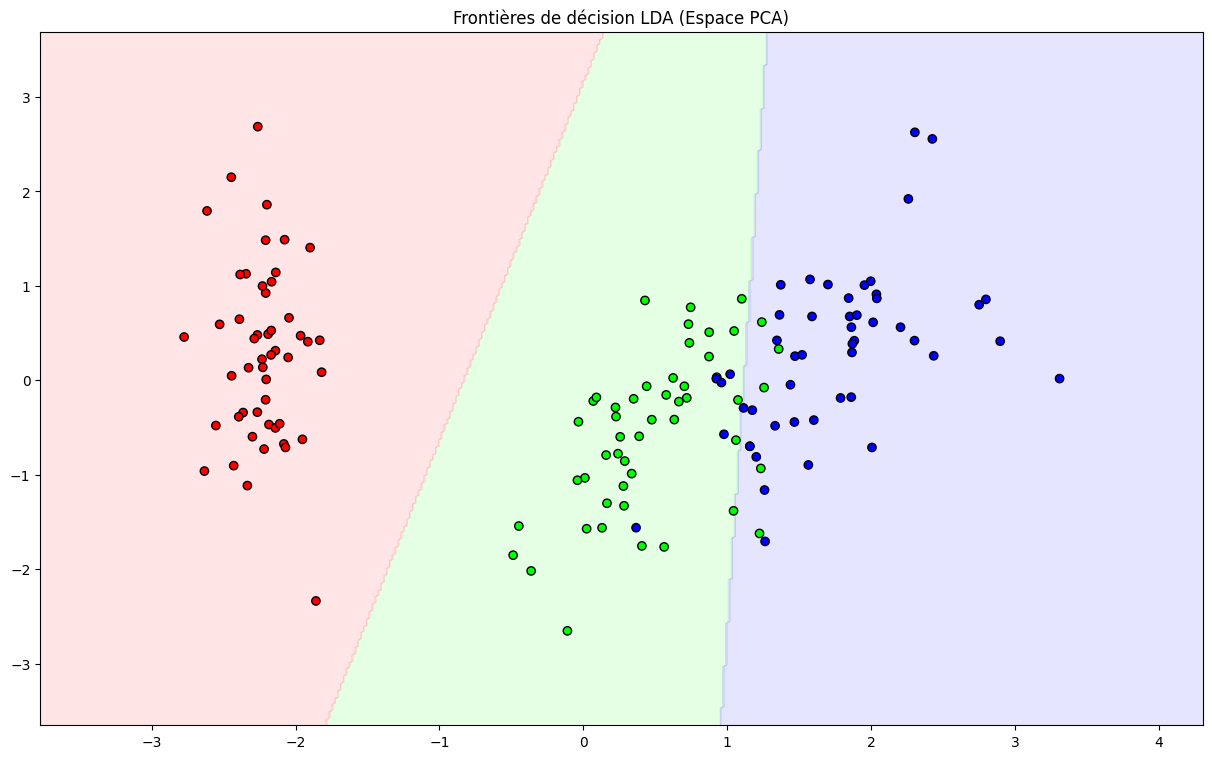

In [2]:
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from matplotlib.colors import ListedColormap

# 9. Pipeline avec Validation Croisée pour LDA
# Au lieu de juste entraîner, on vérifie la robustesse sur 5 segments (folds)
pipeline = make_pipeline(StandardScaler(), LDA())
scores = cross_val_score(pipeline, X, y, cv=5)
print(f"Précision moyenne par validation croisée : {scores.mean():.2f} (+/- {scores.std():.2f})")

# 10. Visualisation des frontières de décision (Le "Wow Effect")
# Cette partie montre visuellement comment LDA sépare l'espace,
def plot_decision_boundary(X, y, model, title):
    # Création d'une grille pour colorier les zones
    h = .02
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(xx, yy, Z, alpha=0.3, cmap=ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF']))
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolor='k', cmap=ListedColormap(['#FF0000', '#00FF00', '#0000FF']))
    plt.title(title)
    plt.show()

# Entraînement sur PCA 2D pour visualiser la limite
lda_2d = LDA().fit(pc, y)
plot_decision_boundary(pc, y, lda_2d, "Frontières de décision LDA (Espace PCA)")